# M5.5 · 执行质量评估（TCA）

> 交易成本不只是佣金。执行落差（Implementation Shortfall）衡量「纸面理想组合」与「实际执行」之间的全部差距，
> 并分解为延迟、市场冲击与机会成本，是评估执行算法、选择经纪商的核心工具。

## 一、核心概念

1. **到达价（Arrival Price）**：订单下达时的市场价格，作为执行基准；
2. **VWAP**：执行时段成交量加权平均价，衡量是否跑赢市场均价；
3. **执行落差（Perold 1988）**：纸面组合按决策价全成交，实际因延迟、冲击、未成交而跑输，分解为：
   - **延迟成本**：决策价 → 到达价（下单前价格漂移）；
   - **市场冲击**：到达价 → 实际成交价（自身交易推动价格）；
   - **机会成本**：未成交部分错过的后续收益。

## 二、执行落差分解

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
from bt_lab2 import tca
isr = tca.implementation_shortfall('BUY', decision_px=10.0, arrival_px=10.05,
                                   fill_px=10.12, filled_qty=8000, total_qty=10000,
                                   final_px=10.30)
print('执行落差 IS=%.1f bps' % isr['is_bps'])
for k, lab in [('delay_cost', '延迟成本'), ('impact_cost', '市场冲击'),
               ('opportunity_cost', '机会成本')]:
    print('%s = %.1f 元' % (lab, isr[k]))
eq = tca.execution_quality_table('BUY', 10.05, 10.12, 10.10)
print('相对到达价=%.1f bps，相对市场VWAP=%.1f bps' % (eq['vs_arrival_bps'], eq['vs_vwap_bps']))
print('VWAP 算例=%.3f' % tca.vwap([10, 10.1, 10.2], [3, 5, 2]))

执行落差 IS=166.0 bps
延迟成本 = 500.0 元
市场冲击 = 560.0 元
机会成本 = 600.0 元
相对到达价=69.7 bps，相对市场VWAP=19.8 bps
VWAP 算例=10.090


## 三、可视化

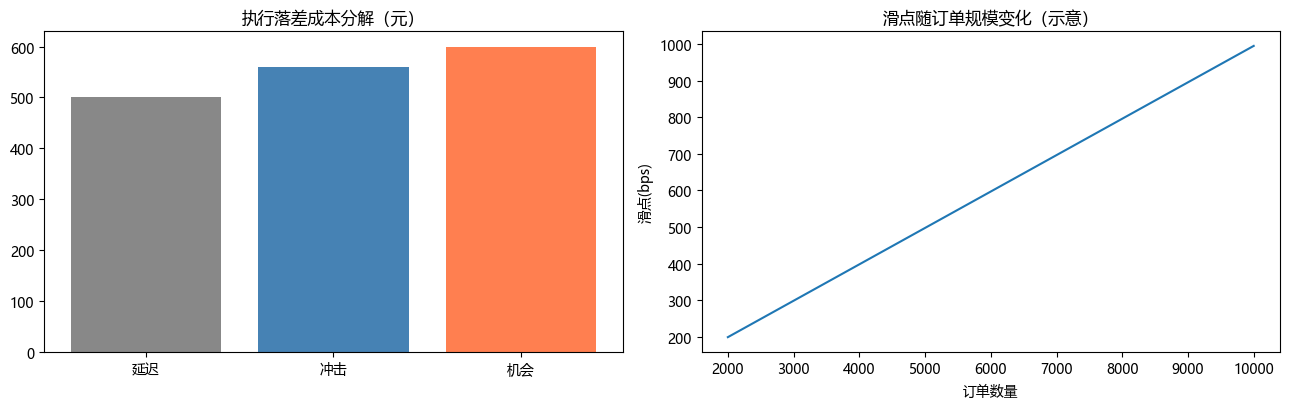

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
labs = ['延迟', '冲击', '机会']; vals = [isr['delay_cost'], isr['impact_cost'], isr['opportunity_cost']]
ax[0].bar(labs, vals, color=['#888', 'steelblue', 'coral']); ax[0].set_title('执行落差成本分解（元）')
sizes = [2000, 5000, 8000, 10000]
ax[1].plot(sizes, [tca.slippage_vs_arrival('BUY', 10.05, 10.05 + 0.0001*s) for s in sizes])
ax[1].set_title('滑点随订单规模变化（示意）'); ax[1].set_xlabel('订单数量'); ax[1].set_ylabel('滑点(bps)')
plt.tight_layout(); plt.show()

## 四、面试要点

- **执行落差为何优于只看 VWAP？** VWAP 只对比市场均价，无法反映未成交的机会成本和决策到下单的延迟；IS 覆盖纸面到实际的全部差距。
- **三项成本如何此消彼长？** 激进执行冲击高但机会成本低；被动/拆单冲击小但延迟与机会成本高，TCA 用于找最优执行节奏。
- **机会成本何时最大？** 流动性不足、限价单未成交而价格快速离开时，错过的收益即机会成本。
- **TCA 如何用于经纪商选择？** 同类订单横向对比各经纪商的 IS/滑点，控制规模与市场环境后评估执行能力。

## 五、练习

1. 改为卖出方向，重算 IS 并核对符号。
2. 把全部订单拆成 TWAP 多笔，比较冲击与机会成本。
3. 用真实分钟数据计算实际 VWAP 滑点。
4. 讨论：开盘集合竞价的执行落差有何特殊性？